<a href="https://colab.research.google.com/github/Mohtasim4458/Artificial-Intelligence/blob/main/AI_LAB_TASK_2_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


========== TASK 1: 8-PUZZLE BFS ==========
Start state:
1 2 3
4 _ 6
7 5 8

Solvable: True
Solution: ['Down', 'Right']
Moves: 2
Nodes expanded: 8
Nodes generated: 16
Time taken: 0.053 ms

Final state:
1 2 3
4 5 6
7 8 _


========== TASK 2: BFS SECOND START STATE ==========
Goal state:
1 2 3
4 5 6
7 8 _

Start state:
8 1 3
4 _ 2
7 6 5

Solution: ['Right', 'Down', 'Left', 'Left', 'Up', 'Up', 'Right', 'Down', 'Left', 'Down', 'Right', 'Up', 'Right', 'Down']
Solution length: 14
Nodes expanded: 5960
Nodes generated: 9021
Time taken: 102.337 ms

========== TASK 3: STEP-BY-STEP SOLUTION ==========
Initial board:
8 1 3
4 _ 2
7 6 5

Move 1: Right
8 1 3
4 2 _
7 6 5

Move 2: Down
8 1 3
4 2 5
7 6 _

Move 3: Left
8 1 3
4 2 5
7 _ 6

Move 4: Left
8 1 3
4 2 5
_ 7 6

Move 5: Up
8 1 3
_ 2 5
4 7 6

Move 6: Up
_ 1 3
8 2 5
4 7 6

Move 7: Right
1 _ 3
8 2 5
4 7 6

Move 8: Down
1 2 3
8 _ 5
4 7 6

Move 9: Left
1 2 3
_ 8 5
4 7 6

Move 10: Down
1 2 3
4 8 5
_ 7 6

Move 11: Right
1 2 3
4 8 5
7 _ 6

Move 12: Up
1 2 

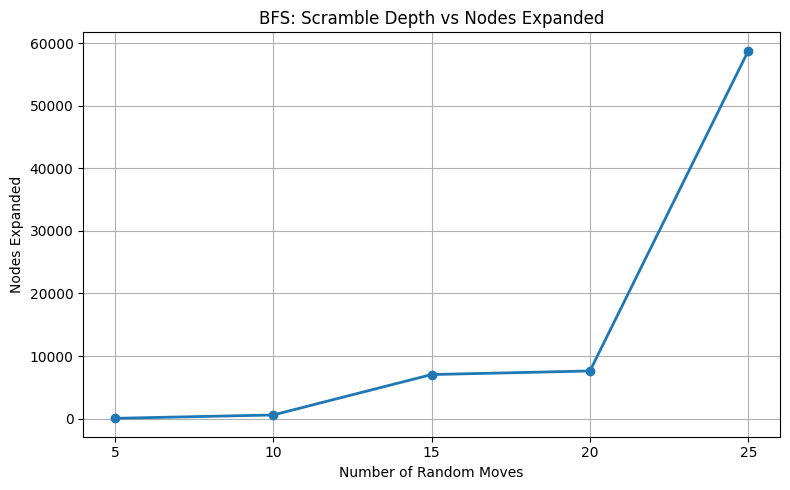

Graph saved as bfs_growth.png

========== TASK 5: UNSOLVABLE PUZZLE ==========
Testing given state:
1 2 3
4 5 6
8 7 _

Solution: None
Nodes expanded: 0
Nodes generated: 0

========== TASK 6: MISSIONARIES AND CANNIBALS ==========
Solution found!
Total crossings: 11
Initial state: (3, 3, 0)
Left bank:  M=3, C=3
Right bank: M=0, C=0
Boat position: Left
-----------------------------------
Step 1: Move 0 missionary/missionaries and 2 cannibal(s)
Left bank:  M=3, C=1
Right bank: M=0, C=2
Boat position: Right
-----------------------------------
Step 2: Move 0 missionary/missionaries and 1 cannibal(s)
Left bank:  M=3, C=2
Right bank: M=0, C=1
Boat position: Left
-----------------------------------
Step 3: Move 0 missionary/missionaries and 2 cannibal(s)
Left bank:  M=3, C=0
Right bank: M=0, C=3
Boat position: Right
-----------------------------------
Step 4: Move 0 missionary/missionaries and 1 cannibal(s)
Left bank:  M=3, C=1
Right bank: M=0, C=2
Boat position: Left
--------------------------

In [3]:

# ==========================================
# AI AGENT LAB - PRACTICE TASKS
# BFS, 8-Puzzle, Performance and Missionaries
# ==========================================

from collections import deque
import time
import random
import matplotlib.pyplot as plt


# ==========================================
# COMMON 8-PUZZLE FUNCTIONS
# ==========================================

GOAL = (1, 2, 3,
        4, 5, 6,
        7, 8, 0)

MOVES = {
    "Up": -3,
    "Down": 3,
    "Left": -1,
    "Right": 1
}

OPPOSITE = {
    "Up": "Down",
    "Down": "Up",
    "Left": "Right",
    "Right": "Left"
}


# Check whether puzzle is solvable
def is_solvable(state):
    tiles = [x for x in state if x != 0]

    inversions = sum(
        1
        for i in range(len(tiles))
        for j in range(i + 1, len(tiles))
        if tiles[i] > tiles[j]
    )

    return inversions % 2 == 0


# Find legal moves
def actions(state):
    i = state.index(0)
    row, col = divmod(i, 3)
    legal = []

    if row > 0:
        legal.append("Up")
    if row < 2:
        legal.append("Down")
    if col > 0:
        legal.append("Left")
    if col < 2:
        legal.append("Right")

    return legal


# Generate next state
def result(state, action):
    i = state.index(0)
    j = i + MOVES[action]

    new_state = list(state)
    new_state[i], new_state[j] = new_state[j], new_state[i]

    return tuple(new_state)


# Display puzzle
def show(state):
    for i in range(0, 9, 3):
        print(" ".join(
            "_" if x == 0 else str(x)
            for x in state[i:i + 3]
        ))
    print()


# Breadth-First Search
def solve_bfs(start):
    if not is_solvable(start):
        return None, 0, 0

    frontier = deque([(start, [])])
    explored = {start}
    expanded = 0
    generated = 1

    while frontier:
        state, path = frontier.popleft()

        if state == GOAL:
            return path, expanded, generated

        expanded += 1

        for action in actions(state):
            child = result(state, action)

            if child not in explored:
                explored.add(child)
                generated += 1
                frontier.append((child, path + [action]))

    return None, expanded, generated


# ==========================================
# TASK 1: 8-PUZZLE BFS WITH EXECUTION TIME
# ==========================================

print("\n========== TASK 1: 8-PUZZLE BFS ==========")

start = (1, 2, 3,
         4, 0, 6,
         7, 5, 8)

print("Start state:")
show(start)

print("Solvable:", is_solvable(start))

if is_solvable(start):

    t0 = time.perf_counter()

    path, expanded, generated = solve_bfs(start)

    t1 = time.perf_counter()

    if path is not None:
        print("Solution:", path)
        print("Moves:", len(path))
        print("Nodes expanded:", expanded)
        print("Nodes generated:", generated)
        print(f"Time taken: {(t1-t0)*1000:.3f} ms")

        final_state = start

        for move in path:
            final_state = result(final_state, move)

        print("\nFinal state:")
        show(final_state)


# ==========================================
# TASK 2: 8-PUZZLE WITH ANOTHER START STATE
# ==========================================

print("\n========== TASK 2: BFS SECOND START STATE ==========")

start2 = (8, 1, 3,
          4, 0, 2,
          7, 6, 5)

print("Goal state:")
show(GOAL)

print("Start state:")
show(start2)

if is_solvable(start2):

    t0 = time.perf_counter()

    path2, expanded2, generated2 = solve_bfs(start2)

    elapsed = (time.perf_counter() - t0) * 1000

    print("Solution:", path2)
    print("Solution length:", len(path2))
    print("Nodes expanded:", expanded2)
    print("Nodes generated:", generated2)
    print(f"Time taken: {elapsed:.3f} ms")

else:
    print("Puzzle is unsolvable.")


# ==========================================
# TASK 3: DISPLAY SOLUTION STEP BY STEP
# ==========================================

print("\n========== TASK 3: STEP-BY-STEP SOLUTION ==========")


def print_solution(start, path):

    if path is None:
        print("No solution exists.")
        return

    state = start

    print("Initial board:")
    show(state)

    for step, action in enumerate(path, start=1):

        state = result(state, action)

        print(f"Move {step}: {action}")
        show(state)

    print("Puzzle solved!")


print_solution(start2, path2)


# ==========================================
# TASK 4: BFS PERFORMANCE COMPARISON
# ==========================================

print("\n========== TASK 4: BFS PERFORMANCE ==========")


def random_scramble(number_of_moves, rng):

    state = GOAL
    previous_action = None

    for _ in range(number_of_moves):

        legal = actions(state)

        if previous_action is not None:
            legal.remove(OPPOSITE[previous_action])

        action = rng.choice(legal)

        state = result(state, action)

        previous_action = action

    return state


rng = random.Random(42)

depths = [5, 10, 15, 20, 25]

solution_depths = []
nodes_expanded = []
nodes_generated = []

print("-" * 66)
print(
    f"{'Scramble Depth':<16}"
    f"{'Solution Depth':<16}"
    f"{'Nodes Expanded':<17}"
    f"{'Nodes Generated':<17}"
)
print("-" * 66)

for depth in depths:

    start_random = random_scramble(depth, rng)

    path, expanded, generated = solve_bfs(start_random)

    actual_depth = len(path) if path is not None else None

    solution_depths.append(actual_depth)
    nodes_expanded.append(expanded)
    nodes_generated.append(generated)

    print(
        f"{depth:<16}"
        f"{str(actual_depth):<16}"
        f"{expanded:<17}"
        f"{generated:<17}"
    )

    print("Starting state:", start_random)
    print()


# Plot graph
plt.figure(figsize=(8, 5))

plt.plot(
    depths,
    nodes_expanded,
    marker="o",
    linewidth=2
)

plt.title("BFS: Scramble Depth vs Nodes Expanded")
plt.xlabel("Number of Random Moves")
plt.ylabel("Nodes Expanded")
plt.xticks(depths)
plt.grid(True)
plt.tight_layout()

plt.savefig("bfs_growth.png", dpi=150)

plt.show()

print("Graph saved as bfs_growth.png")


# ==========================================
# TASK 5: TEST UNSOLVABLE 8-PUZZLE
# ==========================================

print("\n========== TASK 5: UNSOLVABLE PUZZLE ==========")

unsolvable = (1, 2, 3,
              4, 5, 6,
              8, 7, 0)

print("Testing given state:")
show(unsolvable)

path3, expanded3, generated3 = solve_bfs(unsolvable)

print("Solution:", path3)
print("Nodes expanded:", expanded3)
print("Nodes generated:", generated3)


# ==========================================
# TASK 6: MISSIONARIES AND CANNIBALS USING BFS
# ==========================================

print("\n========== TASK 6: MISSIONARIES AND CANNIBALS ==========")

# State:
# (missionaries_left, cannibals_left, boat_position)

INITIAL = (3, 3, 0)
MC_GOAL = (0, 0, 1)

# Possible boat passengers
MC_ACTIONS = [
    (1, 0),
    (2, 0),
    (0, 1),
    (0, 2),
    (1, 1)
]


# Check valid state
def is_valid(state):

    m_left, c_left, boat = state

    m_right = 3 - m_left
    c_right = 3 - c_left

    if not (0 <= m_left <= 3 and 0 <= c_left <= 3):
        return False

    if boat not in (0, 1):
        return False

    if m_left > 0 and c_left > m_left:
        return False

    if m_right > 0 and c_right > m_right:
        return False

    return True


# Goal test
def mc_goal_test(state):
    return state == MC_GOAL


# Find legal actions
def mc_actions(state):

    m_left, c_left, boat = state

    legal = []

    for m, c in MC_ACTIONS:

        if boat == 0:

            if m <= m_left and c <= c_left:

                new_state = (
                    m_left - m,
                    c_left - c,
                    1
                )

                if is_valid(new_state):
                    legal.append((m, c))

        else:

            m_right = 3 - m_left
            c_right = 3 - c_left

            if m <= m_right and c <= c_right:

                new_state = (
                    m_left + m,
                    c_left + c,
                    0
                )

                if is_valid(new_state):
                    legal.append((m, c))

    return legal


# Transition model
def mc_result(state, action):

    m_left, c_left, boat = state

    m, c = action

    if boat == 0:
        return (m_left - m, c_left - c, 1)

    return (m_left + m, c_left + c, 0)


# BFS for Missionaries and Cannibals
def solve_mc_bfs(start):

    if not is_valid(start):
        return None

    frontier = deque([(start, [])])

    explored = {start}

    while frontier:

        state, path = frontier.popleft()

        if mc_goal_test(state):
            return path

        for action in mc_actions(state):

            child = mc_result(state, action)

            if child not in explored:

                explored.add(child)

                frontier.append(
                    (child, path + [(action, child)])
                )

    return None


# Display state
def print_mc_state(state):

    m_left, c_left, boat = state

    m_right = 3 - m_left
    c_right = 3 - c_left

    boat_side = "Left" if boat == 0 else "Right"

    print(f"Left bank:  M={m_left}, C={c_left}")
    print(f"Right bank: M={m_right}, C={c_right}")
    print(f"Boat position: {boat_side}")
    print("-" * 35)


# Display solution
def print_mc_solution(start, path):

    if path is None:
        print("No solution found.")
        return

    print("Initial state:", start)
    print_mc_state(start)

    for step, (action, state) in enumerate(path, start=1):

        m, c = action

        print(
            f"Step {step}: Move {m} missionary/missionaries "
            f"and {c} cannibal(s)"
        )

        print_mc_state(state)

    print("Goal reached!")


# Run program
mc_path = solve_mc_bfs(INITIAL)

if mc_path is not None:

    print("Solution found!")
    print("Total crossings:", len(mc_path))

    print_mc_solution(INITIAL, mc_path)

else:
    print("No solution exists.")


# ==========================================
# END OF AI AGENT LAB PRACTICE
# ==========================================

print("\nALL TASKS COMPLETED!")
